## Model training & evaluation

This notebook evaluate whether sentence-level QE scores improve the prediction of temporal post-editing effort beyond a simple baseline.

Multiple linear regression is used as the primary prediction model. Models are trained and evaluated separately for each target language (arabic, dutch, italian, turkish, ukrainian, vietnamese) using 10-fold document grouped cross validation.

The baseline model uses MT length and MT system as predictors.

The analysis first examines whether linear regression is a reasonable moelling choice, then generates out of sample predictions, evaluates model performance using Spearman's rho and MAE; then compares each QE specification with the baseline.

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

file_path ='/Users/tuedungtruong/Documents/PythonProjects/msc-thesis/data/processed/divemt_model_input.tsv'
model_df_processed = pd.read_csv(file_path, sep ='\t')

fig_dir = "/Users/tuedungtruong/Documents/PythonProjects/msc-thesis/results/figures"
os.makedirs(fig_dir, exist_ok = True)

lang_order =['ara','nld','ita','tur','ukr','vie']
lang_names = {'ara':'Arabic','nld':'Dutch','ita':'Italian','tur':'Turkish','ukr':'Ukrainian','vie':'Vietnamese'}

qe_order = ['cometkiwi','gemba_gemma','gemba_gpt']
qe_names = {'cometkiwi':'CometKiwi','gemba_gemma':'GEMBA-MQM (Gemma 3 27B)','gemba_gpt':'GEMBA-MQM (GPT-4.1 mini)'}



## 1. Assess suitability of linear regression

Inspect the dependent variable `edit_time` and its relationship with the main baseline predictor MT length `mt_len_wrd` to assess the distribution of temporal PE effort.

In [47]:
model_df_processed.groupby('lang_id')['edit_time'].describe()

,count,mean,std,min,25%,50%,75%,max
lang_id,,,,,,,,
ara,858.0,104.913619,187.515800,2.477,30.54500,57.1490,106.15275,2254.138
ita,860.0,88.875769,94.162217,0.985,30.61350,65.1775,115.67475,1380.862
nld,860.0,61.600501,96.234772,0.685,18.98450,42.6425,76.42850,2000.656
tur,860.0,64.546573,85.009380,0.359,23.65925,44.5075,78.63300,1650.252
ukr,860.0,137.105870,141.400191,1.079,56.99650,101.2095,168.61650,2412.522
vie,849.0,128.725649,180.105763,6.324,47.75900,80.8620,143.62300,2428.047


#### Distribution of editing time for each language


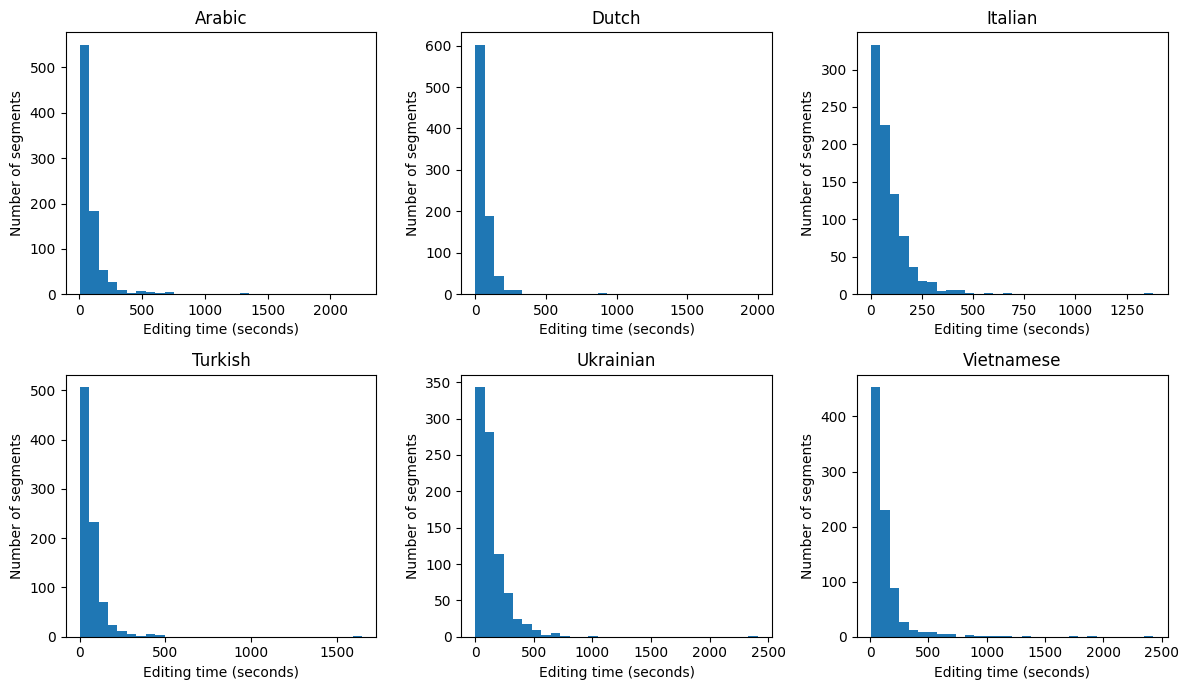

In [48]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, lang in zip(axes.flatten(),lang_order):
    values = model_df_processed.loc[model_df_processed['lang_id'] == lang,'edit_time']

    ax.hist(values, bins=30)
    ax.set_title(lang_names[lang])
    ax.set_xlabel('Editing time (seconds)')
    ax.set_ylabel('Number of segments')

plt.tight_layout()
#fig.savefig(os.path.join(fig_dir, '1_editing_time_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()

**Observation:** Editing time is strongly right-skewed across all 6 target languages. Most observations are concentrated at shorter editing times, while a smaller number of segments require substantially longer editing times. The 45-minute outlier threshold reduces the most extreme observations but does not remove the right-skewed structure of the outcome.

#### Relationship between MT length (main predictor of baseline model) and editing time

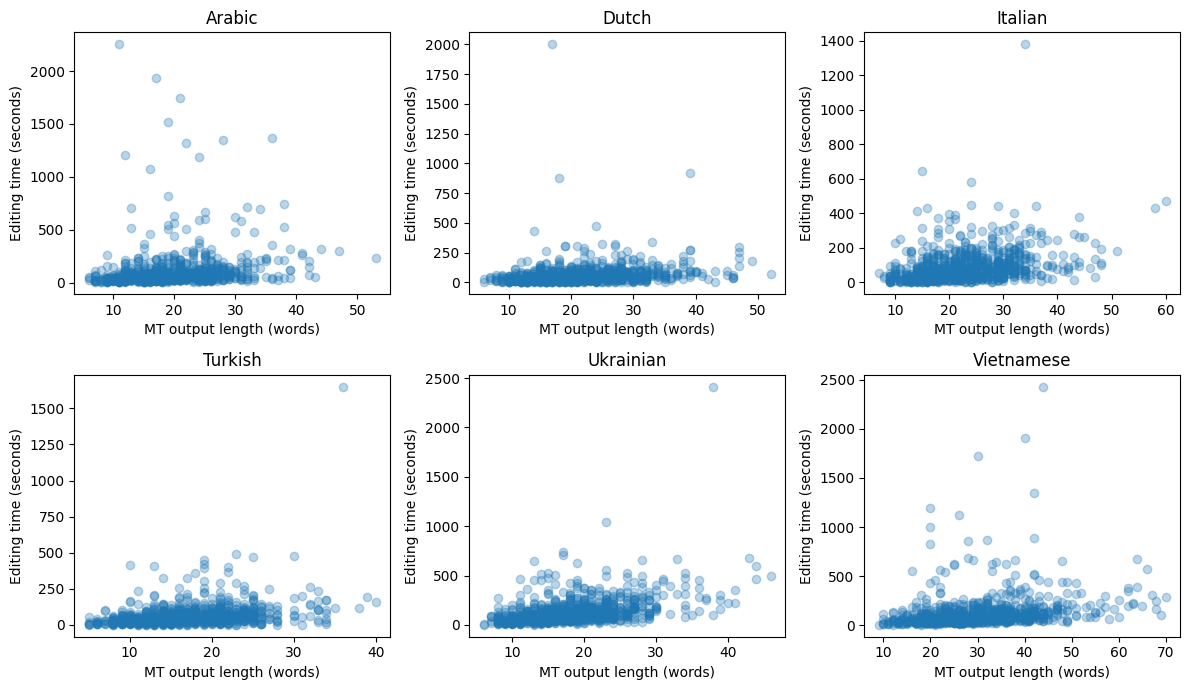

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, lang in zip(axes.flatten(), lang_order):
    lang_df = model_df_processed.loc[model_df_processed['lang_id'] == lang]

    ax.scatter(lang_df['mt_len_wrd'],lang_df['edit_time'],alpha=0.3)
    ax.set_title(lang_names[lang])
    ax.set_xlabel('MT output length (words)')
    ax.set_ylabel('Editing time (seconds)')

plt.tight_layout()
#fig.savefig(os.path.join(fig_dir, '2_MT_length_vs_edit_time_correlation.png'), dpi=300, bbox_inches='tight')
plt.show()

**Observation:** MT length shows a positive but noisy relationship with editing time across all 6 languages. Longer MT segments generally require more editing time, although the variation in editing time also increases with sentence length. No strong curved relationship is immediately apparent, so a linear relationship remains a plausible simple baseline.

#### Relationship between each QE predictor and editing time


In [50]:
predictors = ['qe_cometkiwi','qe_gemba_gemma3','qe_gemba_gpt4_1_mini']

for predictor in predictors:
    rho = model_df_processed[[predictor, 'edit_time']].corr(method='spearman').iloc[0, 1]
    print(predictor, rho)

qe_cometkiwi -0.359423991176063
qe_gemba_gemma3 -0.32351524291603445
qe_gemba_gpt4_1_mini -0.3288218114314875


In [51]:
numeric_predictors = [
    'mt_len_wrd',
    'mt_system',
    'qe_cometkiwi',
    'qe_gemba_gemma3',
    'qe_gemba_gpt4_1_mini'
]

model_df_processed[numeric_predictors].corr()

,mt_len_wrd,mt_system,qe_cometkiwi,qe_gemba_gemma3,qe_gemba_gpt4_1_mini
mt_len_wrd,1.000000,-0.019057,-0.056914,-0.013130,-0.051840
mt_system,-0.019057,1.000000,-0.190073,-0.316852,-0.346905
qe_cometkiwi,-0.056914,-0.190073,1.000000,0.537762,0.514793
qe_gemba_gemma3,-0.013130,-0.316852,0.537762,1.000000,0.622317
qe_gemba_gpt4_1_mini,-0.051840,-0.346905,0.514793,0.622317,1.000000


## 2. Define document-grouped cross-validation splits 

Create reusable train-test split using 10-fold GroupKFold cross-validation. `doc_id` is used as the grouping variable so that sentences from the same document cannot occur in both the training and test sets within a fold.

The same saved folds are reused for the baseline and all QE model specifications across all target languages so that performance comparisons are made on identical held-out observations.

In [52]:
import sklearn as sk
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr

In [53]:
language_splits = {}

for lang in model_df_processed['lang_id'].unique():
    lang_df = model_df_processed.loc[model_df_processed['lang_id']==lang].copy()
    doc_id = lang_df['doc_id']
    gkf = GroupKFold (n_splits=10)
    splits = list(gkf.split(lang_df, groups = doc_id))
    language_splits[lang] = splits

## 3. Define reusable cross-validation modelling function

Create a function called `run_cv_model()` that takes in lang_df, splits, feature_cols as parameters.

It trains and evaluates one regression specification across the 10 predefined folds for a single target language.

For each fold, the function fits a multiple linear regression model on the training observations, generates predictions for the held-out observations, and calculates Spearman's rho and MAE. It also stores the observed and predicted editing time for every held-out segment for later analysis

In [54]:
def run_cv_model(lang_df, splits, feature_cols, log_target = False):
    
    fold_results = []
    prediction_results =[]

    X = lang_df[feature_cols]
    y = lang_df['edit_time']

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]
        if log_target:
            y_train_model = np.log1p(y_train)
        else:
            y_train_model = y_train

        model = LinearRegression()
        model.fit(X_train,y_train_model)
        y_pred_model= model.predict(X_test)

        if log_target:
            y_pred = np.expm1(y_pred_model)
        else:
            y_pred = y_pred_model

        mae = mean_absolute_error(y_test, y_pred)
        rho, p_value = spearmanr(y_test, y_pred)

        fold_results.append({
            'fold': fold,
            'mae': mae,
            'spearman_rho': rho,
            'spearman_p': p_value
            })
        # Raw prediction for every test observation
        test_rows = lang_df.iloc[test_idx]

        for unit_id, doc_id, actual, predicted in zip(test_rows['unit_id'],test_rows['doc_id'],y_test,y_pred):
            prediction_results.append({
                'unit_id': unit_id,
                'doc_id': doc_id,
                'fold': fold,
                'actual_edit_time': actual,
                'predicted_edit_time': predicted
            })

    return (
        pd.DataFrame(fold_results),
        pd.DataFrame(prediction_results)
    )
        

### Define model specifications

Evaluate 4 predictor sets using the same regression model. The baseline contains MT length and MT system (binary encoded). Each alternative specification retains these predictors and adds one sentence-level QE score.


In [55]:
#Define features for each prediction model
feature_sets = {
    'baseline': ['mt_len_wrd', 'mt_system'],
    'cometkiwi': ['mt_len_wrd','mt_system','qe_cometkiwi'],
    'gemba_gemma': ['mt_len_wrd','mt_system','qe_gemba_gemma3'],
    'gemba_gpt': ['mt_len_wrd','mt_system','qe_gemba_gpt4_1_mini']
    }

## 4. Run cross-validated regression models

Languages: Arabic (ara), Italian (ita), Dutch (nld), Turkish (tur), Ukrainian (ukr), Vietnamese (vie)

Model class: Multiple linear regression

Dependent variable: `edit_time` => this is used to inspect the behaviour of linear regression on the original time scale and is retained as a sensitivity analysis 

Models & their features:
1. Baseline: MT length, MT system 
2. Extended model with Pretrained QE: COMETKiwi QE score, MT length, MT system
3. Extended model with LLM-based QE (1): QE score generated by Open-weight model (Gemma 3 27B) using GEMBA-MQM framework, MT length, MT system
4. Extended model with LLM-based QE (2): QE score generated by Proprietary model (OpenAI ChatGPT-4.1-mini) using GEMBA-MQM framework, MT length, MT system


The 4 regression specifications are fitted separately for all 6 target languages using the defined GroupKFold splits.

This produces two outputs:

- fold level performance results containing Spearman's rho and MAE
- observation level out of sample predictions containing actual and predicted editing time

Because the same folds are used for all 4 specifications, subsequent comparisons with the baseline are paired by language and fold.


In [56]:
all_results = []
all_predictions =[]
for lang in model_df_processed['lang_id'].unique():
    lang_df = model_df_processed.loc[model_df_processed['lang_id']==lang].copy()
    fold = language_splits [lang]

    for model, features in feature_sets.items():
        fold_result, predictions = run_cv_model (lang_df = lang_df, splits = fold, feature_cols = features)

        fold_result['lang_id'] =lang
        fold_result['model'] = model

        predictions['lang_id'] =lang
        predictions['model'] = model

        all_results.append(fold_result)
        all_predictions.append(predictions)


results_df = pd.concat(
    all_results,
    ignore_index=True
)

predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)


In [57]:
print(results_df.shape)
print(results_df.head(10))

(240, 6)
   fold        mae  spearman_rho    spearman_p lang_id     model
0     1  42.579809      0.394785  1.410707e-04     tur  baseline
1     2  36.464302      0.366984  4.365540e-04     tur  baseline
2     3  26.917462      0.617867  1.427666e-10     tur  baseline
3     4  46.569510      0.396029  1.337955e-04     tur  baseline
4     5  34.712020      0.458154  7.172640e-06     tur  baseline
5     6  51.284120      0.509935  3.881135e-07     tur  baseline
6     7  36.809080      0.470533  8.166044e-06     tur  baseline
7     8  33.808672      0.453706  1.861568e-05     tur  baseline
8     9  55.971701      0.450960  2.120883e-05     tur  baseline
9    10  37.329330      0.533916  1.197621e-07     tur  baseline


In [58]:
# Create summary table across the 10 folds for the untransformed edit-time model
raw_summary = (
    results_df
    .groupby(['lang_id', 'model'])
    .agg(
        mean_spearman=('spearman_rho', 'mean'),
        std_spearman=('spearman_rho', 'std'),
        mean_mae=('mae', 'mean'),
        std_mae=('mae', 'std')
    )
    .reset_index()
)

print(raw_summary.shape)
raw_summary

(24, 6)


,lang_id,model,mean_spearman,std_spearman,mean_mae,std_mae
0,ara,baseline,0.468584,0.140927,80.833186,14.730322
1,ara,cometkiwi,0.542956,0.101222,78.041535,13.594557
2,ara,gemba_gemma,0.476702,0.099471,79.704927,13.860330
3,ara,gemba_gpt,0.512490,0.103990,78.921849,13.612751
4,ita,baseline,0.397253,0.072532,56.444111,7.081851
5,ita,cometkiwi,0.487178,0.083953,53.602100,6.230583
6,ita,gemba_gemma,0.447453,0.080642,55.484336,5.833441
7,ita,gemba_gpt,0.475166,0.102616,54.149555,5.982870
8,nld,baseline,0.379295,0.077502,42.006722,9.852693
9,nld,cometkiwi,0.416033,0.084805,41.402634,9.769927


#### Analyses assumptions of linear regression in baseline model

Create residuals plot to check for homoscedasticity



In [59]:
predictions_df['residual'] = (predictions_df['actual_edit_time']- predictions_df['predicted_edit_time'])

baseline_predictions = predictions_df.loc[predictions_df['model'] == 'baseline'].copy()
baseline_predictions.head(10)

,unit_id,doc_id,fold,actual_edit_time,predicted_edit_time,lang_id,model,residual
0,flores101-main-tur-105-pe2-1,105,1,20.462,75.950099,tur,baseline,-55.488099
1,flores101-main-tur-105-pe2-2,105,1,81.336,90.009912,tur,baseline,-8.673912
2,flores101-main-tur-105-pe2-3,105,1,87.411,43.143867,tur,baseline,44.267133
3,flores101-main-tur-23-pe2-1,23,1,43.433,80.636703,tur,baseline,-37.203703
4,flores101-main-tur-23-pe2-2,23,1,31.584,52.517076,tur,baseline,-20.933076
5,flores101-main-tur-23-pe2-3,23,1,412.619,43.143867,tur,baseline,369.475133
6,flores101-main-tur-23-pe2-4,23,1,138.563,66.576890,tur,baseline,71.986110
7,flores101-main-tur-23-pe2-5,23,1,396.594,85.323308,tur,baseline,311.270692
8,flores101-main-tur-7-pe2-1,7,1,67.680,43.143867,tur,baseline,24.536133
9,flores101-main-tur-7-pe2-2,7,1,43.162,66.576890,tur,baseline,-23.414890


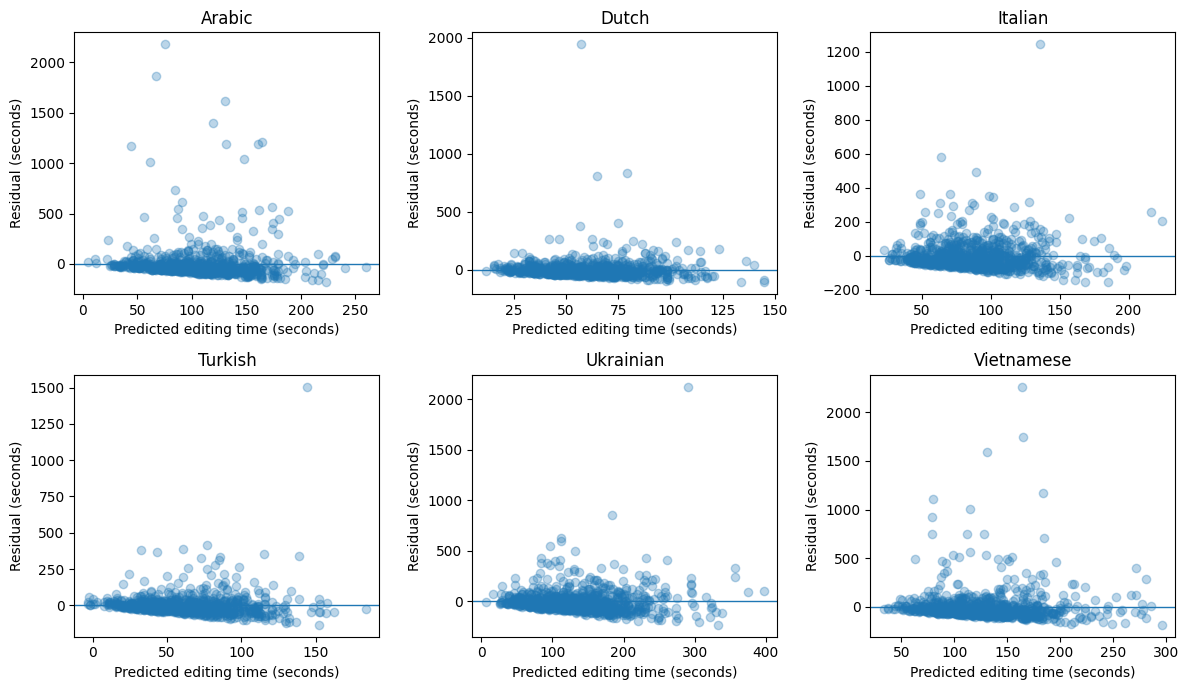

In [60]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, lang in zip(axes.flatten(), lang_order):
    lang_pred = baseline_predictions.loc[baseline_predictions['lang_id'] == lang]

    ax.scatter(lang_pred['predicted_edit_time'],lang_pred['residual'],alpha=0.3)
    ax.axhline(0, linewidth=1)
    ax.set_title(lang_names[lang])
    ax.set_xlabel('Predicted editing time (seconds)')
    ax.set_ylabel('Residual (seconds)')

plt.tight_layout()
#fig.savefig(os.path.join(fig_dir, '3_residuals_raw_baseline.png'), dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The residual plots show a wider spread of prediction errors as predicted editing time increases across all 6 languages. This means the error variance is not constant. Several large positive residuals also shows that the model underpredicts some segments with high editing time. Considering the strongly right-skewed distributions of editing time, modelling editing time on its original scale might not fully represent the data => might need a sensitivity analysis with log transformed `edit_time`

## 5. Primary analysis: log-transformed editing time

The primary linear regression models use `log(1+edit_time)` as the dependent variable because the original editing time values are strongly right-skewed and the untransformed baseline model shows heteroscedastic residuals. 

The full experiment is repeated using the same predictor sets, target langauges and document-grouped cross validation fols. Predictions are transformed back to seconds before MAE is calculated, while Spearman's rho is used to evaluate the ranking of relative PE effort.

The models fitted to untransformed editing time are retained as a sensitivity analysis to assess whether the main dinfings depend on the target transformation.

In [61]:
log_all_results = []
log_all_predictions = []
for lang in model_df_processed['lang_id'].unique():

    lang_df = model_df_processed.loc[model_df_processed['lang_id'] == lang].copy()

    splits = language_splits[lang]

    for model, features in feature_sets.items():

        fold_result, predictions = run_cv_model(
            lang_df=lang_df,
            splits=splits,
            feature_cols=features,
            log_target=True
        )

        fold_result['lang_id'] = lang
        fold_result['model'] = model

        predictions['lang_id'] = lang
        predictions['model'] = model

        log_all_results.append(fold_result)
        log_all_predictions.append(predictions)

In [62]:
log_results_df = pd.concat(log_all_results,ignore_index=True)

log_predictions_df = pd.concat(log_all_predictions,ignore_index=True)
print(log_results_df.shape)
print(log_predictions_df.shape)

(240, 6)
(20588, 7)


In [63]:
# Create log summary table across the 10 folds
log_summary = (log_results_df.groupby(['lang_id', 'model'])
               .agg(mean_spearman=('spearman_rho', 'mean'),
                    std_spearman=('spearman_rho', 'std'),
                    mean_mae=('mae','mean'),
                    std_mae=('mae','std')).reset_index())
log_summary

,lang_id,model,mean_spearman,std_spearman,mean_mae,std_mae
0,ara,baseline,0.464438,0.144322,67.451964,16.332740
1,ara,cometkiwi,0.536772,0.114849,68.310838,18.497669
2,ara,gemba_gemma,0.491844,0.117271,66.926148,16.488186
3,ara,gemba_gpt,0.515916,0.110081,66.249576,15.683393
4,ita,baseline,0.396207,0.076414,53.791110,8.481569
5,ita,cometkiwi,0.482302,0.080402,52.645507,8.913902
6,ita,gemba_gemma,0.440542,0.079717,53.401670,8.127748
7,ita,gemba_gpt,0.473102,0.095742,52.360721,8.738869
8,nld,baseline,0.382452,0.087113,38.905929,11.836324
9,nld,cometkiwi,0.427220,0.093552,38.592911,11.896457


In [64]:
log_baseline = (log_results_df.loc[log_results_df['model'] == 'baseline',['lang_id', 'fold', 'spearman_rho', 'mae']].rename(columns={'spearman_rho': 'baseline_rho','mae': 'baseline_mae'}))
log_qe = (log_results_df.loc[log_results_df['model'] != 'baseline'].copy())
log_qe = log_qe.rename(columns={'spearman_rho': 'qe_rho','mae': 'qe_mae'})
print(log_baseline.shape)
print(log_qe.shape)

(60, 4)
(180, 6)


In [65]:
log_delta_df = log_qe.merge(log_baseline,on=['lang_id','fold'], how='left')

log_delta_df['delta_rho'] = (log_delta_df['qe_rho']- log_delta_df['baseline_rho'])
log_delta_df['delta_mae'] = (log_delta_df['qe_mae']- log_delta_df['baseline_mae'])


In [66]:
# Create log delta summary table across the 10 folds
log_delta_summary = (log_delta_df.groupby(['lang_id', 'model'])
                     .agg(
                        baseline_mean_rho = ('baseline_rho','mean'),
                        qe_mean_rho =('qe_rho','mean'),
                        mean_delta_rho = ('delta_rho','mean'),
                        std_delta_rho = ('delta_rho','std'),
                        
                        baseline_mean_mae = ('baseline_mae','mean'),
                        qe_mean_mae =('qe_mae','mean'),
                        mean_delta_mae = ('delta_mae','mean'),
                        std_delta_mae = ('delta_mae','std')).reset_index()
                        )
log_delta_summary

,lang_id,model,baseline_mean_rho,qe_mean_rho,mean_delta_rho,std_delta_rho,baseline_mean_mae,qe_mean_mae,mean_delta_mae,std_delta_mae
0,ara,cometkiwi,0.464438,0.536772,0.072334,0.058210,67.451964,68.310838,0.858875,3.237347
1,ara,gemba_gemma,0.464438,0.491844,0.027406,0.042350,67.451964,66.926148,-0.525815,1.155010
2,ara,gemba_gpt,0.464438,0.515916,0.051478,0.051291,67.451964,66.249576,-1.202388,1.228878
3,ita,cometkiwi,0.396207,0.482302,0.086094,0.060459,53.791110,52.645507,-1.145604,2.240394
4,ita,gemba_gemma,0.396207,0.440542,0.044335,0.026793,53.791110,53.401670,-0.389440,1.510582
5,ita,gemba_gpt,0.396207,0.473102,0.076894,0.065514,53.791110,52.360721,-1.430389,1.698699
6,nld,cometkiwi,0.382452,0.427220,0.044768,0.036663,38.905929,38.592911,-0.313018,1.131240
7,nld,gemba_gemma,0.382452,0.413197,0.030745,0.020309,38.905929,38.905586,-0.000343,0.855192
8,nld,gemba_gpt,0.382452,0.426843,0.044391,0.043757,38.905929,38.488736,-0.417193,0.991999
9,tur,cometkiwi,0.463680,0.504255,0.040575,0.050706,37.266983,36.467399,-0.799583,1.428356


In [67]:
log_predictions_df['residual'] = (log_predictions_df['actual_edit_time']- log_predictions_df['predicted_edit_time'])

log_baseline_predictions = log_predictions_df.loc[log_predictions_df['model'] == 'baseline'].copy()

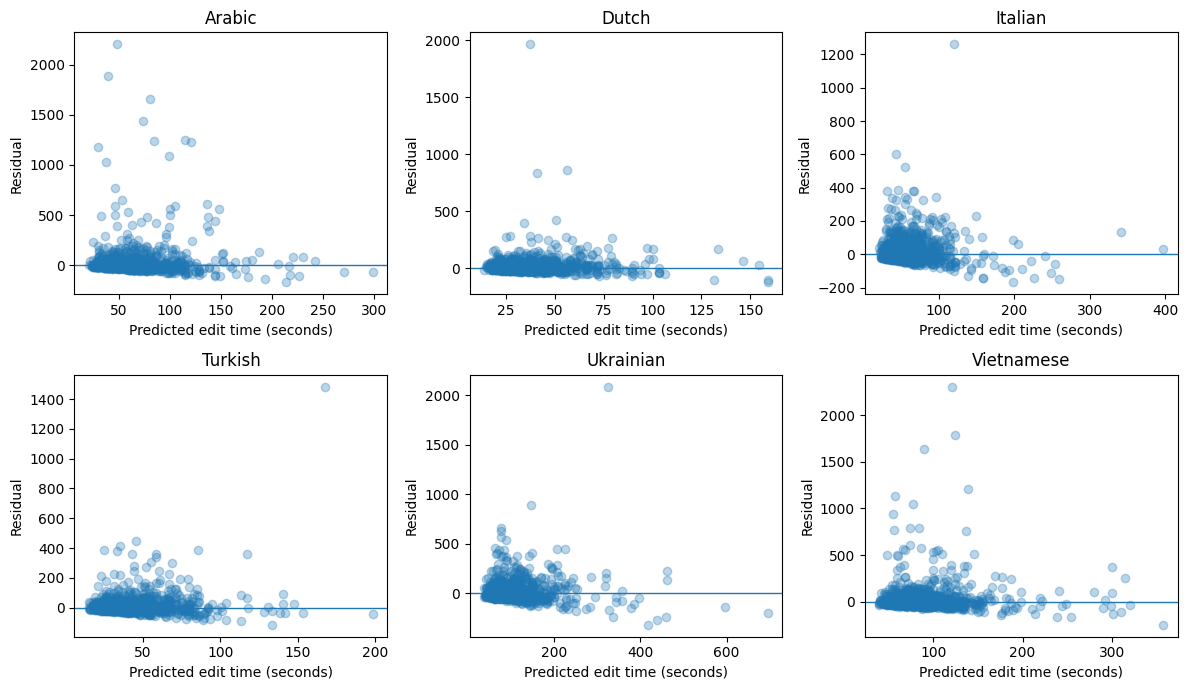

In [68]:
# Not used in the thesis: log-target residuals converted back to seconds
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, lang in zip(axes.flatten(), lang_order):

    lang_pred = log_baseline_predictions.loc[log_baseline_predictions['lang_id'] == lang]

    ax.scatter(lang_pred['predicted_edit_time'],lang_pred["residual"],alpha=0.3)

    ax.axhline(0, linewidth=1)

    ax.set_title(lang_names[lang])
    ax.set_xlabel("Predicted edit time (seconds)")
    ax.set_ylabel("Residual")

plt.tight_layout()
plt.show()

In [69]:
log_baseline_predictions = log_predictions_df.loc[log_predictions_df['model'] == 'baseline'].copy()

log_baseline_predictions['actual_log_time'] = np.log1p(log_baseline_predictions['actual_edit_time'])

log_baseline_predictions['predicted_log_time'] = np.log1p(log_baseline_predictions['predicted_edit_time'])

log_baseline_predictions['log_residual'] = (log_baseline_predictions['actual_log_time']- log_baseline_predictions['predicted_log_time'])

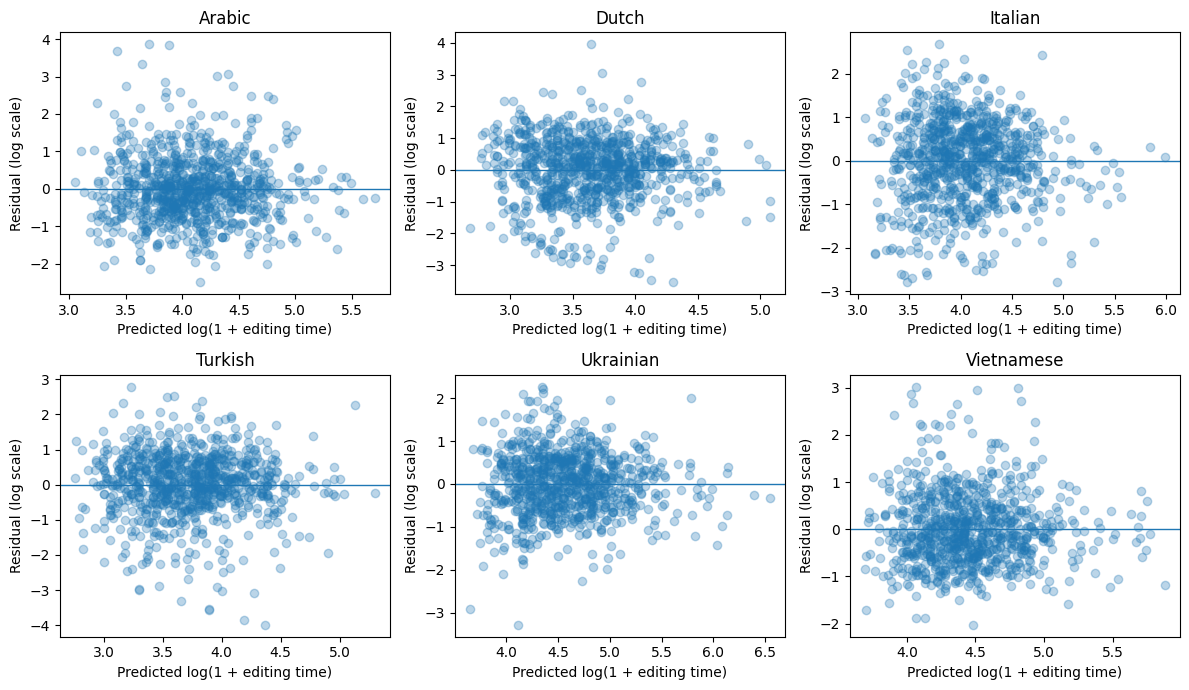

In [70]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, lang in zip(
    axes.flatten(),
    lang_order
):

    lang_pred = log_baseline_predictions.loc[
        log_baseline_predictions["lang_id"] == lang
    ]

    ax.scatter(
        lang_pred["predicted_log_time"],
        lang_pred["log_residual"],
        alpha=0.3
    )

    ax.axhline(0, linewidth=1)

    ax.set_title(lang_names[lang])
    ax.set_xlabel("Predicted log(1 + editing time)")
    ax.set_ylabel("Residual (log scale)")

plt.tight_layout()
#fig.savefig(os.path.join(fig_dir, '4_residuals_log_baseline.png'), dpi=300, bbox_inches='tight')
plt.show()

## Models Evaluation

## 6. Compare QE predictor models against the baseline



Use the log transformed editing time models as the primary analysis. Compare each QE model with the baseline from the same language and cross-validation fold.

For Spearman's rho, a positive delta indicates improved ranking performance relative to the baseline. 

For MAE, a negative delta indicates lower prediction error after predictions are transformed back to seconds.

The euqivalent results from the untransformed editing time models are retained for the sensitivity comparison.

In [71]:
#Create df with only baseline result
baseline_df = (results_df.loc[results_df['model']=='baseline',['fold','lang_id','spearman_rho','mae']].rename(columns = {'spearman_rho':'baseline_rho','mae':'baseline_mae'}))
baseline_df.head()

,fold,lang_id,baseline_rho,baseline_mae
0,1,tur,0.394785,42.579809
1,2,tur,0.366984,36.464302
2,3,tur,0.617867,26.917462
3,4,tur,0.396029,46.569510
4,5,tur,0.458154,34.712020


In [72]:
#Create df with only QE results
qe_results_df = results_df.loc[results_df['model'] != 'baseline',['fold','model','lang_id','spearman_rho','spearman_p','mae']].rename(columns={'spearman_rho':'qe_rho','spearman_p':'qe_rho_p','mae':'qe_mae'}).copy()
qe_results_df.head()

,fold,model,lang_id,qe_rho,qe_rho_p,qe_mae
10,1,cometkiwi,tur,0.397644,1.248750e-04,42.649000
11,2,cometkiwi,tur,0.448593,1.168927e-05,33.385820
12,3,cometkiwi,tur,0.658924,2.975330e-12,27.187780
13,4,cometkiwi,tur,0.402927,9.938628e-05,45.371553
14,5,cometkiwi,tur,0.524092,1.602484e-07,34.296930


In [73]:
#Match QE results to baseline result from the same language and same fold
delta_df = qe_results_df.merge(baseline_df, on =['lang_id','fold'], how ='left', validate = 'many_to_one')
delta_df.head()

,fold,model,lang_id,qe_rho,qe_rho_p,qe_mae,baseline_rho,baseline_mae
0,1,cometkiwi,tur,0.397644,1.248750e-04,42.649000,0.394785,42.579809
1,2,cometkiwi,tur,0.448593,1.168927e-05,33.385820,0.366984,36.464302
2,3,cometkiwi,tur,0.658924,2.975330e-12,27.187780,0.617867,26.917462
3,4,cometkiwi,tur,0.402927,9.938628e-05,45.371553,0.396029,46.569510
4,5,cometkiwi,tur,0.524092,1.602484e-07,34.296930,0.458154,34.712020


In [74]:
#Calculate the differences between model with QE inputs and baseline
delta_df['delta_rho'] = (delta_df['qe_rho']- delta_df['baseline_rho'])

delta_df['delta_mae'] =  (delta_df['qe_mae']- delta_df['baseline_mae'])
delta_df.head()


,fold,model,lang_id,qe_rho,qe_rho_p,qe_mae,baseline_rho,baseline_mae,delta_rho,delta_mae
0,1,cometkiwi,tur,0.397644,1.248750e-04,42.649000,0.394785,42.579809,0.002859,0.069191
1,2,cometkiwi,tur,0.448593,1.168927e-05,33.385820,0.366984,36.464302,0.081609,-3.078482
2,3,cometkiwi,tur,0.658924,2.975330e-12,27.187780,0.617867,26.917462,0.041056,0.270317
3,4,cometkiwi,tur,0.402927,9.938628e-05,45.371553,0.396029,46.569510,0.006898,-1.197957
4,5,cometkiwi,tur,0.524092,1.602484e-07,34.296930,0.458154,34.712020,0.065938,-0.415090


In [75]:
delta_summary = (
    delta_df
    .groupby(['lang_id','model'])
    .agg(
        baseline_mean_rho = ('baseline_rho', 'mean'),
        qe_mean_rho = ('qe_rho','mean'),
        mean_delta_rho = ('delta_rho','mean'),
        std_delta_rho = ('delta_rho','std'),
        baseline_mean_mae = ('baseline_mae', 'mean'),
        qe_mean_mae = ('qe_mae','mean'),
        mean_delta_mae = ('delta_mae','mean'),
        std_delta_mae = ('delta_mae','std')
    )
    .reset_index()
)
delta_summary

#delta_summary.to_csv("../results/linear_regression_delta_summary.tsv",sep="\t",index=False)

,lang_id,model,baseline_mean_rho,qe_mean_rho,mean_delta_rho,std_delta_rho,baseline_mean_mae,qe_mean_mae,mean_delta_mae,std_delta_mae
0,ara,cometkiwi,0.468584,0.542956,0.074372,0.080709,80.833186,78.041535,-2.791651,2.991744
1,ara,gemba_gemma,0.468584,0.476702,0.008118,0.079575,80.833186,79.704927,-1.128258,2.803599
2,ara,gemba_gpt,0.468584,0.512490,0.043906,0.053693,80.833186,78.921849,-1.911336,1.830628
3,ita,cometkiwi,0.397253,0.487178,0.089925,0.061053,56.444111,53.602100,-2.842011,2.248416
4,ita,gemba_gemma,0.397253,0.447453,0.050200,0.031688,56.444111,55.484336,-0.959775,1.837898
5,ita,gemba_gpt,0.397253,0.475166,0.077913,0.070974,56.444111,54.149555,-2.294556,2.682966
6,nld,cometkiwi,0.379295,0.416033,0.036737,0.026875,42.006722,41.402634,-0.604088,0.729959
7,nld,gemba_gemma,0.379295,0.400570,0.021275,0.011401,42.006722,41.800635,-0.206087,0.400128
8,nld,gemba_gpt,0.379295,0.421055,0.041760,0.030750,42.006722,41.323663,-0.683058,0.903901
9,tur,cometkiwi,0.465287,0.496860,0.031574,0.035149,40.244601,39.311082,-0.933518,1.064486


In [76]:
sensitivity_comparison = delta_summary[
    ["lang_id", "model", "mean_delta_rho", "mean_delta_mae"]
].merge(
    log_delta_summary[
        ["lang_id", "model", "mean_delta_rho", "mean_delta_mae"]
    ],
    on=["lang_id", "model"],
    suffixes=("_raw", "_log")
)

sensitivity_comparison

,lang_id,model,mean_delta_rho_raw,mean_delta_mae_raw,mean_delta_rho_log,mean_delta_mae_log
0,ara,cometkiwi,0.074372,-2.791651,0.072334,0.858875
1,ara,gemba_gemma,0.008118,-1.128258,0.027406,-0.525815
2,ara,gemba_gpt,0.043906,-1.911336,0.051478,-1.202388
3,ita,cometkiwi,0.089925,-2.842011,0.086094,-1.145604
4,ita,gemba_gemma,0.050200,-0.959775,0.044335,-0.389440
5,ita,gemba_gpt,0.077913,-2.294556,0.076894,-1.430389
6,nld,cometkiwi,0.036737,-0.604088,0.044768,-0.313018
7,nld,gemba_gemma,0.021275,-0.206087,0.030745,-0.000343
8,nld,gemba_gpt,0.041760,-0.683058,0.044391,-0.417193
9,tur,cometkiwi,0.031574,-0.933518,0.040575,-0.799583


In [77]:
#Fold level variation in the primary model with log transformed editing time as target
log_delta_df.groupby(['lang_id','model'])['delta_rho'].agg(['mean','std','min','max'])


mean       std       min       max
lang_id model                                              
ara     cometkiwi    0.072334  0.058210 -0.010527  0.186770
        gemba_gemma  0.027406  0.042350 -0.046734  0.077359
        gemba_gpt    0.051478  0.051291 -0.033576  0.121383
ita     cometkiwi    0.086094  0.060459 -0.019255  0.164492
        gemba_gemma  0.044335  0.026793  0.009715  0.085160
        gemba_gpt    0.076894  0.065514 -0.029314  0.151765
nld     cometkiwi    0.044768  0.036663  0.001634  0.090540
        gemba_gemma  0.030745  0.020309 -0.004284  0.061498
        gemba_gpt    0.044391  0.043757 -0.018699  0.121701
tur     cometkiwi    0.040575  0.050706 -0.023873  0.128667
        gemba_gemma  0.010727  0.035242 -0.036903  0.057894
        gemba_gpt    0.025542  0.028879 -0.017894  0.069396
ukr     cometkiwi    0.027541  0.025334 -0.013023  0.074001
        gemba_gemma  0.018711  0.022359 -0.022810  0.045241
        gemba_gpt    0.026866  0.021106 -0.017655  0.061460
vie     cometkiwi    0.089999  0.051312 -0.003929  0.179120
        gemba_gemma  0.040641  0.037355 -0.044270  0.086975
        gemba_gpt    0.042326  0.041894 -0.024840  0.112885

In [78]:
# Number of folds where QE improves Spearman's rho in the primary log-target model
log_consistency_df = (log_delta_df.groupby(['lang_id', 'model'])
                      .agg(n_folds=('delta_rho', 'size'),
                           positive_rho_folds=('delta_rho', lambda x: (x > 0).sum()),
                           negative_rho_folds=('delta_rho', lambda x: (x < 0).sum()),
                           median_delta_rho=('delta_rho', 'median')).reset_index())

log_consistency_df['pct_positive_rho'] = (log_consistency_df['positive_rho_folds']/ log_consistency_df['n_folds']* 100)
log_consistency_df

,lang_id,model,n_folds,positive_rho_folds,negative_rho_folds,median_delta_rho,pct_positive_rho
0,ara,cometkiwi,10,9,1,0.064662,90.0
1,ara,gemba_gemma,10,8,2,0.033106,80.0
2,ara,gemba_gpt,10,8,2,0.053769,80.0
3,ita,cometkiwi,10,9,1,0.099914,90.0
4,ita,gemba_gemma,10,10,0,0.045983,100.0
5,ita,gemba_gpt,10,8,2,0.094218,80.0
6,nld,cometkiwi,10,10,0,0.046997,100.0
7,nld,gemba_gemma,10,9,1,0.033013,90.0
8,nld,gemba_gpt,10,9,1,0.031661,90.0
9,tur,cometkiwi,10,8,2,0.029949,80.0


In [79]:
# Number of folds where QE reduces MAE in the primary log-target model
log_mae_consistency_df = (log_delta_df.groupby(['lang_id', 'model'])
                          .agg(improved_mae_folds=('delta_mae', lambda x: (x < 0).sum()),
                               worse_mae_folds=('delta_mae', lambda x: (x > 0).sum()),
                               median_delta_mae=('delta_mae', 'median')).reset_index())
log_mae_consistency_df

,lang_id,model,improved_mae_folds,worse_mae_folds,median_delta_mae
0,ara,cometkiwi,6,4,-0.203820
1,ara,gemba_gemma,7,3,-0.725263
2,ara,gemba_gpt,9,1,-0.971629
3,ita,cometkiwi,8,2,-0.949409
4,ita,gemba_gemma,6,4,-0.653550
5,ita,gemba_gpt,8,2,-1.909379
6,nld,cometkiwi,7,3,-0.605329
7,nld,gemba_gemma,7,3,-0.103356
8,nld,gemba_gpt,7,3,-0.534522
9,tur,cometkiwi,8,2,-0.338272


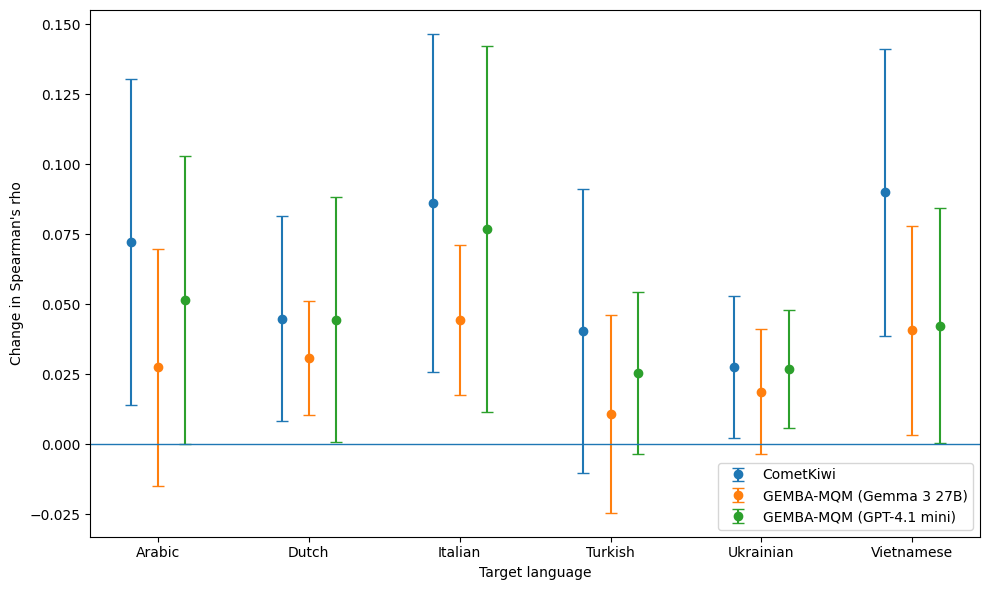

In [80]:
languages = lang_order

models = qe_order

labels = qe_names

x = np.arange(len(languages))
offsets = [-0.18, 0, 0.18]

fig, ax = plt.subplots(figsize=(10, 6))

for offset, model in zip(offsets, models):
    plot_df = (
        log_delta_summary[
            log_delta_summary['model'] == model
        ]
        .set_index('lang_id')
        .loc[languages]
    )

    ax.errorbar(
        x + offset,
        plot_df['mean_delta_rho'],
        yerr=plot_df['std_delta_rho'],
        fmt='o',
        capsize=4,
        label=labels[model]
    )

ax.axhline(0, linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels([lang_names[lang] for lang in languages])
ax.set_xlabel('Target language')
ax.set_ylabel("Change in Spearman's rho")

ax.legend()
plt.tight_layout()
#fig.savefig(os.path.join(fig_dir, '5_delta_spearman.png'), dpi=300, bbox_inches='tight')
plt.show()

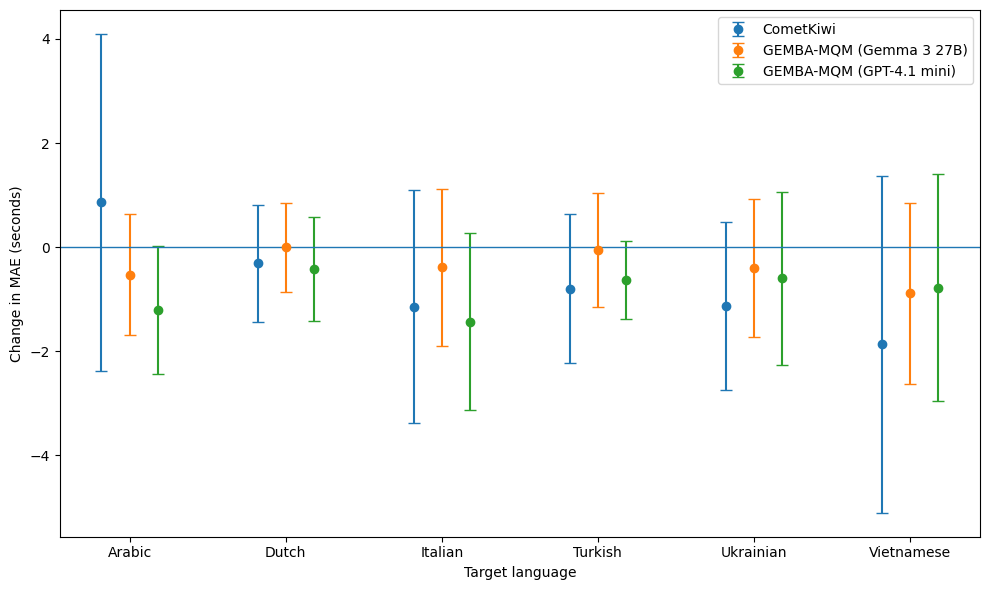

In [81]:
# Change in MAE relative to baseline for the primary log-target model
fig, ax = plt.subplots(figsize=(10, 6))

for offset, model in zip(offsets, models):
    plot_df = (
        log_delta_summary[
            log_delta_summary['model'] == model
        ]
        .set_index('lang_id')
        .loc[languages]
    )

    ax.errorbar(
        x + offset,
        plot_df['mean_delta_mae'],
        yerr=plot_df['std_delta_mae'],
        fmt='o',
        capsize=4,
        label=labels[model]
    )

ax.axhline(0, linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels([lang_names[lang] for lang in languages])

ax.set_xlabel('Target language')
ax.set_ylabel('Change in MAE (seconds)')

ax.legend()
plt.tight_layout()
#fig.savefig(os.path.join(fig_dir, '6_delta_mae.png'), dpi=300, bbox_inches='tight')
plt.show()

Sensitivity comparison with untransformed editing time
Repeat the baseline-versus-QE comparison using the models fitted to untransformed edit_time, then compare the results with the primary log-target models.

In [82]:
# Create dataframe with baseline results from the untransformed edit-time model
raw_baseline_df = (
    results_df.loc[
        results_df['model'] == 'baseline',
        ['fold', 'lang_id', 'spearman_rho', 'mae']
    ]
    .rename(columns={
        'spearman_rho': 'baseline_rho',
        'mae': 'baseline_mae'
    })
)

raw_baseline_df.head()

,fold,lang_id,baseline_rho,baseline_mae
0,1,tur,0.394785,42.579809
1,2,tur,0.366984,36.464302
2,3,tur,0.617867,26.917462
3,4,tur,0.396029,46.569510
4,5,tur,0.458154,34.712020


In [83]:
# Create dataframe with QE-model results from the untransformed edit-time model
raw_qe_results_df = (
    results_df.loc[
        results_df['model'] != 'baseline',
        ['fold', 'model', 'lang_id', 'spearman_rho', 'spearman_p', 'mae']
    ]
    .rename(columns={
        'spearman_rho': 'qe_rho',
        'spearman_p': 'qe_rho_p',
        'mae': 'qe_mae'
    })
    .copy()
)

raw_qe_results_df.head()

,fold,model,lang_id,qe_rho,qe_rho_p,qe_mae
10,1,cometkiwi,tur,0.397644,1.248750e-04,42.649000
11,2,cometkiwi,tur,0.448593,1.168927e-05,33.385820
12,3,cometkiwi,tur,0.658924,2.975330e-12,27.187780
13,4,cometkiwi,tur,0.402927,9.938628e-05,45.371553
14,5,cometkiwi,tur,0.524092,1.602484e-07,34.296930


In [84]:
# Match each QE result to the baseline from the same language and fold
raw_delta_df = raw_qe_results_df.merge(
    raw_baseline_df,
    on=['lang_id', 'fold'],
    how='left',
    validate='many_to_one'
)

raw_delta_df.head()

,fold,model,lang_id,qe_rho,qe_rho_p,qe_mae,baseline_rho,baseline_mae
0,1,cometkiwi,tur,0.397644,1.248750e-04,42.649000,0.394785,42.579809
1,2,cometkiwi,tur,0.448593,1.168927e-05,33.385820,0.366984,36.464302
2,3,cometkiwi,tur,0.658924,2.975330e-12,27.187780,0.617867,26.917462
3,4,cometkiwi,tur,0.402927,9.938628e-05,45.371553,0.396029,46.569510
4,5,cometkiwi,tur,0.524092,1.602484e-07,34.296930,0.458154,34.712020


In [85]:
# Calculate QE-minus-baseline differences for the untransformed edit-time model
raw_delta_df['delta_rho'] = (
    raw_delta_df['qe_rho'] - raw_delta_df['baseline_rho']
)

raw_delta_df['delta_mae'] = (
    raw_delta_df['qe_mae'] - raw_delta_df['baseline_mae']
)

raw_delta_df.head()

,fold,model,lang_id,qe_rho,qe_rho_p,qe_mae,baseline_rho,baseline_mae,delta_rho,delta_mae
0,1,cometkiwi,tur,0.397644,1.248750e-04,42.649000,0.394785,42.579809,0.002859,0.069191
1,2,cometkiwi,tur,0.448593,1.168927e-05,33.385820,0.366984,36.464302,0.081609,-3.078482
2,3,cometkiwi,tur,0.658924,2.975330e-12,27.187780,0.617867,26.917462,0.041056,0.270317
3,4,cometkiwi,tur,0.402927,9.938628e-05,45.371553,0.396029,46.569510,0.006898,-1.197957
4,5,cometkiwi,tur,0.524092,1.602484e-07,34.296930,0.458154,34.712020,0.065938,-0.415090


In [86]:
# Summarise QE-minus-baseline differences for the untransformed edit-time model
raw_delta_summary = (
    raw_delta_df
    .groupby(['lang_id', 'model'])
    .agg(
        baseline_mean_rho=('baseline_rho', 'mean'),
        qe_mean_rho=('qe_rho', 'mean'),
        mean_delta_rho=('delta_rho', 'mean'),
        std_delta_rho=('delta_rho', 'std'),
        baseline_mean_mae=('baseline_mae', 'mean'),
        qe_mean_mae=('qe_mae', 'mean'),
        mean_delta_mae=('delta_mae', 'mean'),
        std_delta_mae=('delta_mae', 'std')
    )
    .reset_index()
)

raw_delta_summary

,lang_id,model,baseline_mean_rho,qe_mean_rho,mean_delta_rho,std_delta_rho,baseline_mean_mae,qe_mean_mae,mean_delta_mae,std_delta_mae
0,ara,cometkiwi,0.468584,0.542956,0.074372,0.080709,80.833186,78.041535,-2.791651,2.991744
1,ara,gemba_gemma,0.468584,0.476702,0.008118,0.079575,80.833186,79.704927,-1.128258,2.803599
2,ara,gemba_gpt,0.468584,0.512490,0.043906,0.053693,80.833186,78.921849,-1.911336,1.830628
3,ita,cometkiwi,0.397253,0.487178,0.089925,0.061053,56.444111,53.602100,-2.842011,2.248416
4,ita,gemba_gemma,0.397253,0.447453,0.050200,0.031688,56.444111,55.484336,-0.959775,1.837898
5,ita,gemba_gpt,0.397253,0.475166,0.077913,0.070974,56.444111,54.149555,-2.294556,2.682966
6,nld,cometkiwi,0.379295,0.416033,0.036737,0.026875,42.006722,41.402634,-0.604088,0.729959
7,nld,gemba_gemma,0.379295,0.400570,0.021275,0.011401,42.006722,41.800635,-0.206087,0.400128
8,nld,gemba_gpt,0.379295,0.421055,0.041760,0.030750,42.006722,41.323663,-0.683058,0.903901
9,tur,cometkiwi,0.465287,0.496860,0.031574,0.035149,40.244601,39.311082,-0.933518,1.064486


In [87]:
# Compare the primary log-target results with the untransformed sensitivity model
sensitivity_comparison = raw_delta_summary[
    ['lang_id', 'model', 'mean_delta_rho', 'mean_delta_mae']
].merge(
    log_delta_summary[
        ['lang_id', 'model', 'mean_delta_rho', 'mean_delta_mae']
    ],
    on=['lang_id', 'model'],
    suffixes=('_raw', '_log')
)

sensitivity_comparison

,lang_id,model,mean_delta_rho_raw,mean_delta_mae_raw,mean_delta_rho_log,mean_delta_mae_log
0,ara,cometkiwi,0.074372,-2.791651,0.072334,0.858875
1,ara,gemba_gemma,0.008118,-1.128258,0.027406,-0.525815
2,ara,gemba_gpt,0.043906,-1.911336,0.051478,-1.202388
3,ita,cometkiwi,0.089925,-2.842011,0.086094,-1.145604
4,ita,gemba_gemma,0.050200,-0.959775,0.044335,-0.389440
5,ita,gemba_gpt,0.077913,-2.294556,0.076894,-1.430389
6,nld,cometkiwi,0.036737,-0.604088,0.044768,-0.313018
7,nld,gemba_gemma,0.021275,-0.206087,0.030745,-0.000343
8,nld,gemba_gpt,0.041760,-0.683058,0.044391,-0.417193
9,tur,cometkiwi,0.031574,-0.933518,0.040575,-0.799583


## 7. Inspect QE score distributions

In [88]:
qe_columns = ['qe_cometkiwi','qe_gemba_gemma3','qe_gemba_gpt4_1_mini']
model_df_processed[qe_columns].describe()

,qe_cometkiwi,qe_gemba_gemma3,qe_gemba_gpt4_1_mini
count,5147.000000,5147.000000,5147.000000
mean,0.833735,-5.325432,-8.877987
std,0.069857,7.809825,10.005841
min,0.209202,-25.000000,-25.000000
25%,0.812376,-6.000000,-25.000000
50%,0.858506,-1.000000,-6.000000
75%,0.880869,-1.000000,-1.000000
max,0.910036,0.000000,0.000000


In [89]:
gemba_columns = ['qe_gemba_gemma3','qe_gemba_gpt4_1_mini']

for col in gemba_columns:
    print("\n", col)
    print("Unique scores:",model_df_processed[col].nunique())
    print("% score = 0:",(model_df_processed[col] == 0).mean() * 100)
    print("% score = -25:",(model_df_processed[col] == -25).mean() * 100)


 qe_gemba_gemma3
Unique scores: 14
% score = 0: 22.809403536040413
% score = -25: 12.201282300369147

 qe_gemba_gpt4_1_mini
Unique scores: 16
% score = 0: 24.84942685059258
% score = -25: 26.07344083932388


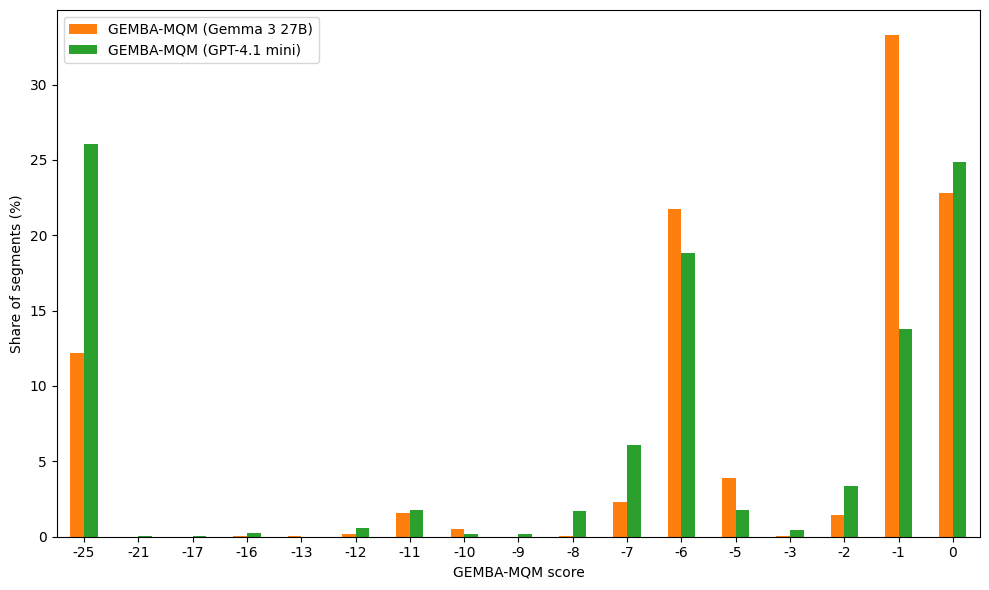

In [90]:
gemba_score_distribution = pd.concat(
    {
    qe_names['gemba_gemma']: model_df_processed['qe_gemba_gemma3'].value_counts(normalize=True).mul(100),
    qe_names['gemba_gpt']: model_df_processed['qe_gemba_gpt4_1_mini'].value_counts(normalize=True).mul(100)
    },
    axis=1
    ).fillna(0).sort_index()

gemba_score_distribution
ax = gemba_score_distribution.plot(kind='bar',figsize=(10,6), color=['C1','C2'])

ax.set_xlabel('GEMBA-MQM score')
ax.set_ylabel('Share of segments (%)')

plt.xticks(rotation=0)
plt.tight_layout()
#ax.figure.savefig(os.path.join(fig_dir, '7_fig_gemba_score_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()



In [91]:
print(log_results_df.shape)
print (log_predictions_df.shape)
print (log_summary.shape)
print(log_delta_df.shape)
print(log_delta_summary.shape)
print(log_consistency_df.shape)
print(log_mae_consistency_df.shape)

(240, 6)
(20588, 8)
(24, 6)
(180, 10)
(18, 10)
(18, 7)
(18, 5)


Store final results

- prediction level = one row per segment/model
- fold level = one row per language/model/fole
- summary level = one row per language/model
- delta level = QE model minus baseline
- sensitivity level = raw time result versus log time result

Files Tracking (for both log edit time & raw edit time model)
- fold results: all results in each fold: spearman, spearman p value, MAE
- actual vs prediction: y, y^ & residuals in each held-out segment
- summary : mean and standard deviation of spearman and MAE for each language in each model
- fold delta: delta between spearman and MAE of each QE model and its baseline
- delta summary : mean and standard deviation of delta
- fold consistency: number of fold in which each QE model improves Spearman or reduce MAE


In [92]:
"""
# Save primary log-target results
log_results_df.to_csv('../results/linear_regression_log_cv_fold_results.tsv', sep='\t', index=False)
log_predictions_df.to_csv('../results/linear_regression_log_cv_actual_vs_predictions.tsv', sep='\t', index=False)
log_summary.to_csv('../results/linear_regression_log_summary.tsv', sep='\t', index=False)
log_delta_df.to_csv('../results/linear_regression_log_fold_deltas.tsv', sep='\t', index=False)
log_delta_summary.to_csv('../results/linear_regression_log_delta_summary.tsv', sep='\t', index=False)
log_consistency_df.to_csv('../results/linear_regression_log_spearman_fold_consistency.tsv', sep='\t', index=False)
log_mae_consistency_df.to_csv('../results/linear_regression_log_mae_fold_consistency.tsv', sep='\t', index=False)

# Save untransformed edit-time sensitivity results
results_df.to_csv('../results/linear_regression_raw_cv_fold_results.tsv', sep='\t', index=False)
predictions_df.to_csv('../results/linear_regression_raw_cv_actual_vs_predictions.tsv', sep='\t', index=False)
raw_summary.to_csv('../results/linear_regression_raw_summary.tsv', sep='\t', index=False)
raw_delta_df.to_csv('../results/linear_regression_raw_fold_deltas.tsv', sep='\t', index=False)
raw_delta_summary.to_csv('../results/linear_regression_raw_delta_summary.tsv', sep='\t', index=False)

# Save direct primary-vs-sensitivity comparison
sensitivity_comparison.to_csv('../results/linear_regression_raw_vs_log_sensitivity.tsv', sep='\t', index=False)
"""

"\n# Save primary log-target results\nlog_results_df.to_csv('../results/linear_regression_log_cv_fold_results.tsv', sep='\t', index=False)\nlog_predictions_df.to_csv('../results/linear_regression_log_cv_actual_vs_predictions.tsv', sep='\t', index=False)\nlog_summary.to_csv('../results/linear_regression_log_summary.tsv', sep='\t', index=False)\nlog_delta_df.to_csv('../results/linear_regression_log_fold_deltas.tsv', sep='\t', index=False)\nlog_delta_summary.to_csv('../results/linear_regression_log_delta_summary.tsv', sep='\t', index=False)\nlog_consistency_df.to_csv('../results/linear_regression_log_spearman_fold_consistency.tsv', sep='\t', index=False)\nlog_mae_consistency_df.to_csv('../results/linear_regression_log_mae_fold_consistency.tsv', sep='\t', index=False)\n\n# Save untransformed edit-time sensitivity results\nresults_df.to_csv('../results/linear_regression_raw_cv_fold_results.tsv', sep='\t', index=False)\npredictions_df.to_csv('../results/linear_regression_raw_cv_actual_vs_pre